In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib widget
%pwd

'/projectnb/batmanlab/mragoza/lung-project/notebooks/copdgene'

In [2]:
import sys, os

print(os.getpid())

os.environ['CUDA_LAUNCH_BLOCKING'] = '1'

def add_path(p: str):
    if p not in sys.path:
        sys.path.append(p)

add_path(os.environ['LP_ROOT'])
add_path(os.environ['PROJECT'])

import project

import torch
assert torch.cuda.is_available()

1048414


# Gather examples

In [3]:
from pathlib import Path

#data_root = Path(os.environ['LP_ROOT']) / 'data' / 'COPDGene'
data_root = Path(os.environ['PRIVATE']) / 'data' / 'COPDGene'

subject_file = data_root / 'sample1000_2025-07-22.csv'
subject_list = project.fileio.load_subject_list(subject_file, key='sid', sep='\t')

bad_subjects = ['23686J', '24634V'] # failed to generate mesh

subject_list = [sid for sid in subject_list if sid not in bad_subjects]

#oom_subjects = ['19760T', '19415C']
#subject_list = oom_subjects

len(subject_list)

Loading /restricted/projectnb/batmanlab/mragoza/data/COPDGene/sample1000_2025-07-22.csv


998

In [4]:
config = project.fileio.load_config('2026-09-15_config.yaml')

data_config = config['dataset']
data_config['subjects'] = subject_list[:1]
data_config['pipeline_tags']['mesh_generation']     = 'rad'
data_config['pipeline_tags']['field_interpolation'] = 'fix'
data_config['pipeline_tags']['forward_simulation']  = 'LE'

project.utils.pprint(data_config)

Loading 2026-09-15_config.yaml
dict(len=6)
├── 'name':          'COPDGene'
├── 'root':          '/restricted/projectnb/batmanlab/mragoza/data/COPDGene'
├── 'subjects':      list(len=1)
|   └── 0: '16514P'
├── 'state_pairs':   list(len=1)
|   └── 0: list(len=2)
├── 'variant':       '2026-09-15'
└── 'pipeline_tags': dict(len=8)
    ├── 'image_resampling':    'iso'
    ├── 'image_segmentation':  'v3d'
    ├── 'image_registration':  'gil'
    ├── 'anatomical_regions':  'lung'
    ├── 'material_properties': 'bela'
    ├── 'mesh_generation':     'rad'
    ├── 'field_interpolation': 'fix'
    └── 'forward_simulation':  'LE'


In [5]:
examples = project.get_examples(data_config)

Gathering examples...
1 total


# Training run

In [6]:
train_config = config['training']
project.utils.pprint(train_config)

dict(len=9)
├── 'seed':       1234
├── 'task':       dict(len=3)
|   ├── 'inputs':  list(len=1)
|   ├── 'targets': list(len=1)
|   └── 'losses':  dict(len=1)
├── 'split':      dict(len=3)
|   ├── 'key':        'category'
|   ├── 'test_ratio': 0.2
|   └── 'val_ratio':  0.1
├── 'transform':  dict(len=8)
|   ├── 'normalize':      True
|   ├── 'image_mean':     0.0
|   ├── 'image_std':      1.0
|   ├── 'apply_mask':     True
|   ├── 'do_augment':     True
|   ├── 'rand_rotate':    True
|   ├── 'rand_reflect':   True
|   └── 'rand_translate': 4.0
├── 'loader':     dict(len=3)
|   ├── 'batch_size':  1
|   ├── 'shuffle':     True
|   └── 'num_workers': 0
├── 'model':      dict(len=2)
|   ├── 'backbone': dict(len=11)
|   └── 'heads':    dict(len=1)
├── 'pde_solver': dict(len=5)
|   ├── 'type':          'warp'
|   ├── 'material_type': 'linear'
|   ├── 'g_vector':      list(len=3)
|   ├── 'relative_loss': True
|   └── 'tv_reg_weight': 1e-05
├── 'optimizer':  dict(len=2)
|   ├── 'type': 'AdamW'
|

In [193]:
import math

train_config = {
    'seed': 1234,
    'task': {
        'inputs':  ['image'],
        'targets': ['E'],
        'losses':  {'E': 'sim'}
    },
    'split': {'method': 'random', 'test_ratio': 0, 'val_ratio': 0},
    'transform': {
        'normalize': True,
        'image_mean': -650.,
        'image_std': 150.,
        'apply_mask': True,
        'do_augment': False,
        'rand_rotate': False,
        'rand_reflect': False,
        'rand_translate': 0.0,
        'use_cache': True
    },
    'loaders': {'batch_size': 1, 'shuffle': True},
    'model': {
        'backbone': {
            'type': 'UNet3D',
            'out_channels': 8,
            'n_conv_units': 2,
            'n_unet_levels': 2,
            'do_downsample': True
        },
        'heads': {
            'E': {
                'mode': 'log10',
                'scale': 1.0,
                'v_loc': 1.5e3,
                'v_min': 0.0,
                'v_max': 1e5
            }
        }
    },
    'optimizer': {'type': 'AdamW', 'lr': 2e-4},
    'pde_solver': {
        'type': 'warp.fem',
        'material_type': 'linear',
        'g_vector': [0, -9.81, 0],
        'relative_loss': True,
        'tv_reg_weight': 1e-4
    },
    'boundary_condition': {'type': 'mesh_key', 'value': 'u_fwd'},
    'trainer': {'num_epochs': 100, 'save_interval': 10}
}

In [194]:
out_name = '2026-10-21_LE_one_ex'

In [195]:
%rm -rf outputs/training/2026-10-21_LE_one_ex

Splitting data examples
Train examples: 1
Test examples:  0
Val examples:   0


Validating training task
Inputs:  ['image']
Targets: ['E']
Losses:  {'E': 'sim'}
Building model architecture
backbone.encoder.unit0.conv.weight                 216	(8, 1, 3, 3, 3)
backbone.encoder.unit0.norm.weight                 8	(8,)
backbone.encoder.unit0.norm.bias                   8	(8,)
backbone.encoder.unit1.conv.weight                 1728	(8, 8, 3, 3, 3)
backbone.encoder.unit1.norm.weight                 8	(8,)
backbone.encoder.unit1.norm.bias                   8	(8,)
backbone.sublevel.encoder.unit0.conv.weight        3456	(16, 8, 3, 3, 3)
backbone.sublevel.encoder.unit0.norm.weight        16	(16,)
backbone.sublevel.encoder.unit0.norm.bias          16	(16,)
backbone.sublevel.encoder.unit1.conv.weight        6912	(16, 16, 3, 3, 3)
backbone.sublevel.encoder.unit1.norm.weight        16	(16,)
backbone.sublevel.encoder.unit1.norm.bias          16	(16,)
backbone.sublevel.sublevel.encoder.unit0.conv.weight 13824	(32, 16, 3, 3, 3)
backbone.sublevel.sublevel.encoder.unit0.norm.weight

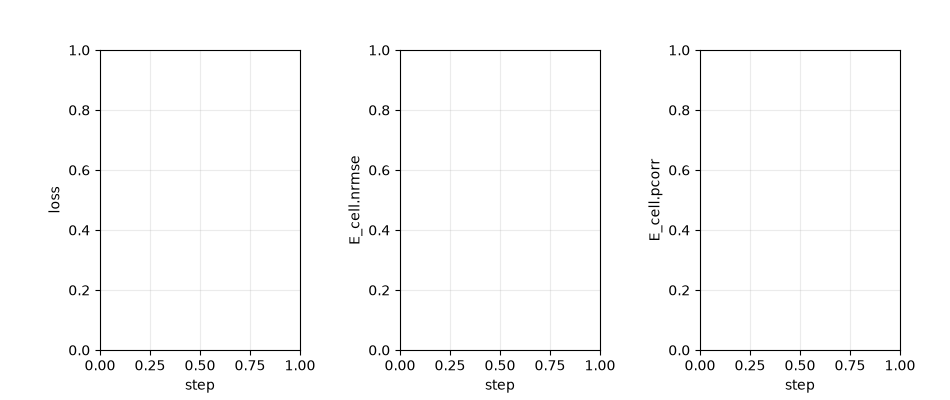

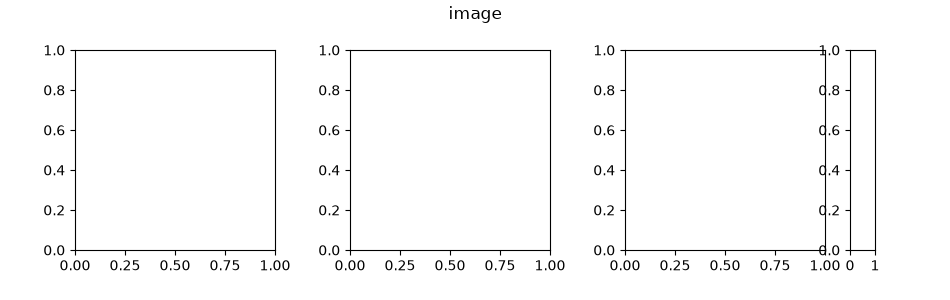

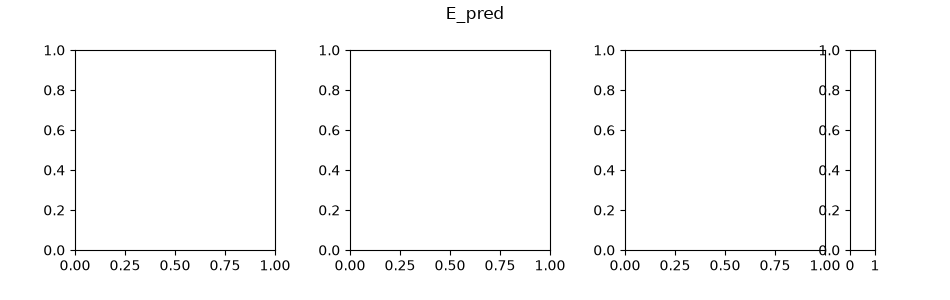

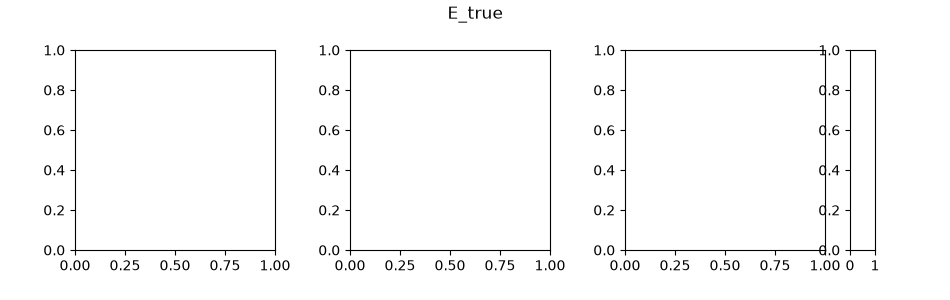

In [196]:
import project.training
trainer = project.training.get_trainer(examples, train_config, out_name)

In [ ]:
trainer.train(num_epochs=100, save_interval=10)

Training start
Saving outputs/training/2026-10-21_LE_one_ex/checkpoint_0.pt
Saving outputs/training/2026-10-21_LE_one_ex/eval_metrics.csv
[Epoch 0 | train batch 1 | load data]  dt = 3.3s  mem_used = 17 GiB  subject = 16514P  img_size = (368, 368, 268)  n_verts = 36174
[Epoch 0 | train batch 1 | run batch]  dt = 2.4s  mem_used = 17 GiB  loss = 0.0002496  grad_norm = 0.106


/projectnb/batmanlab/mragoza/lung-project/project/visual/matplotlib.py:161: UserWarning: Adding colorbar to a different Figure <Figure size 1425x450 with 4 Axes> than <Figure size 1425x450 with 4 Axes> which fig.colorbar is called on.
  plt.colorbar(self.im_k, cax=self.cbar_ax)


[Epoch 1 | train batch 1 | load data]  dt = 0.21s  mem_used = 17 GiB  subject = 16514P  img_size = (368, 368, 268)  n_verts = 36174
[Epoch 1 | train batch 1 | run batch]  dt = 2.2s  mem_used = 17 GiB  loss = 0.0002023  grad_norm = 0.0769
[Epoch 2 | train batch 1 | load data]  dt = 0.21s  mem_used = 17 GiB  subject = 16514P  img_size = (368, 368, 268)  n_verts = 36174
[Epoch 2 | train batch 1 | run batch]  dt = 2.1s  mem_used = 17 GiB  loss = 0.000117  grad_norm = 0.0542
[Epoch 3 | train batch 1 | load data]  dt = 0.2s  mem_used = 17 GiB  subject = 16514P  img_size = (368, 368, 268)  n_verts = 36174
[Epoch 3 | train batch 1 | run batch]  dt = 2.1s  mem_used = 17 GiB  loss = 9.505e-05  grad_norm = 0.02721
[Epoch 4 | train batch 1 | load data]  dt = 0.24s  mem_used = 17 GiB  subject = 16514P  img_size = (368, 368, 268)  n_verts = 36174
[Epoch 4 | train batch 1 | run batch]  dt = 2.1s  mem_used = 17 GiB  loss = 9.257e-05  grad_norm = 0.01656
[Epoch 5 | train batch 1 | load data]  dt = 0.21

In [158]:
import pandas as pd
df = pd.read_csv(f'outputs/training/{out_name}/eval_metrics.csv')
df

,epoch,phase,batch,loss,grad_norm,group,label,num_voxels,E_vox.mean,E_vox.std,...,u_cell.mean,u_cell.std,u_cell.rms,u_cell.mae,u_cell.mre,u_cell.rmse,u_cell.nrmse,res_cell.mean,res_cell.std,res_cell.rms
0,0,train,1,0.000250,0.106047,NaN,NaN,2144006,1475.986136,30.514698,...,0.012761,0.005163,0.013766,0.000329,0.025853,0.000401,0.029261,0.002714,0.004844,0.005553
1,1,train,1,0.000202,0.076893,NaN,NaN,2144006,2069.133740,353.013370,...,0.012854,0.005075,0.013820,0.000272,0.021349,0.000350,0.025526,0.003718,0.006669,0.007635
2,2,train,1,0.000117,0.054218,NaN,NaN,2144006,2066.897298,421.152596,...,0.012731,0.005078,0.013706,0.000203,0.015930,0.000257,0.018788,0.003699,0.006641,0.007601
3,3,train,1,0.000095,0.027225,NaN,NaN,2144006,1941.933194,385.784649,...,0.012732,0.005099,0.013715,0.000184,0.014477,0.000227,0.016605,0.003494,0.006265,0.007173
4,4,train,1,0.000093,0.016556,NaN,NaN,2144006,1794.750300,307.119481,...,0.012764,0.005122,0.013753,0.000190,0.014918,0.000224,0.016392,0.003255,0.005829,0.006676
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,95,train,1,0.000023,0.003486,NaN,NaN,2144006,2265.646819,371.924364,...,0.012745,0.005069,0.013716,0.000068,0.005353,0.000087,0.006322,0.004066,0.007296,0.008353
96,96,train,1,0.000023,0.002487,NaN,NaN,2144006,2268.182261,374.249079,...,0.012739,0.005069,0.013710,0.000066,0.005158,0.000084,0.006122,0.004070,0.007303,0.008361
97,97,train,1,0.000023,0.003402,NaN,NaN,2144006,2285.324419,384.766622,...,0.012710,0.005064,0.013682,0.000065,0.005143,0.000083,0.006095,0.004096,0.007351,0.008415
98,98,train,1,0.000023,0.003843,NaN,NaN,2144006,2282.028937,385.724704,...,0.012708,0.005063,0.013680,0.000066,0.005186,0.000084,0.006122,0.004089,0.007340,0.008403


In [159]:
df.groupby(['epoch', 'phase'])[['loss']].describe()

loss                                                        \
            count      mean std       min       25%       50%       75%   
epoch phase                                                               
0     train   1.0  0.000250 NaN  0.000250  0.000250  0.000250  0.000250   
1     train   1.0  0.000202 NaN  0.000202  0.000202  0.000202  0.000202   
2     train   1.0  0.000117 NaN  0.000117  0.000117  0.000117  0.000117   
3     train   1.0  0.000095 NaN  0.000095  0.000095  0.000095  0.000095   
4     train   1.0  0.000093 NaN  0.000093  0.000093  0.000093  0.000093   
...           ...       ...  ..       ...       ...       ...       ...   
95    train   1.0  0.000023 NaN  0.000023  0.000023  0.000023  0.000023   
96    train   1.0  0.000023 NaN  0.000023  0.000023  0.000023  0.000023   
97    train   1.0  0.000023 NaN  0.000023  0.000023  0.000023  0.000023   
98    train   1.0  0.000023 NaN  0.000023  0.000023  0.000023  0.000023   
99    train   1.0  0.000022 NaN  0.000022  0.000022  0.000022  0.000022   

                       
                  max  
epoch phase            
0     train  0.000250  
1     train  0.000202  
2     train  0.000117  
3     train  0.000095  
4     train  0.000093  
...               ...  
95    train  0.000023  
96    train  0.000023  
97    train  0.000023  
98    train  0.000023  
99    train  0.000022  

[100 rows x 8 columns]

In [160]:
outputs = trainer.run_batch(batch=next(iter(trainer.train_loader)), eval_mode=True)

In [170]:
import numpy as np

affine = outputs['batch']['affine'][0].detach().cpu().numpy()
image  = outputs['batch']['image'][0,0].detach().cpu().numpy()
mask   = outputs['batch']['mask'][0,0].detach().cpu().numpy()
E_true = outputs['batch']['E'][0,0].detach().cpu().numpy()
E_pred = outputs['preds']['E'][0,0].detach().cpu().numpy()

vox_spacing = tuple(float(v) for v in affine[:3,:3] @ np.ones(3))
vox_spacing

(-1.0, 1.0, 1.0)

In [171]:
mesh = outputs['batch']['mesh'][0]

def check_interpolation(mesh, mask, affine):
    from project.common import transforms, interpolation
    mask = torch.as_tensor(mask, dtype=float, device='cuda')[None,...]
    affine = torch.as_tensor(affine, device='cuda')
    points = torch.as_tensor(mesh.points, device='cuda')
    voxels = transforms.world_to_voxel_coords(points, affine)
    values = interpolation.interpolate_tensor(mask, voxels)[:,0]
    return values.detach().cpu().numpy()

check_interpolation(mesh, mask, affine).min() # 0.3282

np.float64(0.3282492728635748)

In [163]:
import project.visual.matplotlib as mpl_viz
import matplotlib.pyplot as plt

img_kws = dict(cmap='gray', vmin=-1000, vmax=-500)
E_t_kws = dict(cmap='jet', vmin=0, vmax=1e4)
E_p_kws = dict(cmap='jet', vmin=0, vmax=1e4)
err_kws = dict(cmap='seismic', vmin=-1, vmax=1)

grid_kws = dict(cbar_width=0.2, padding=(0.5, 0.65, 0.35, 0.3))

In [164]:
import numpy as np

img_m = image * mask
E_t_m = E_true * mask
E_p_m = E_pred * mask

err_m = np.log10(np.maximum(E_pred / E_true, 1e-12)) * mask

z = E_true.shape[-1] // 2
z

134

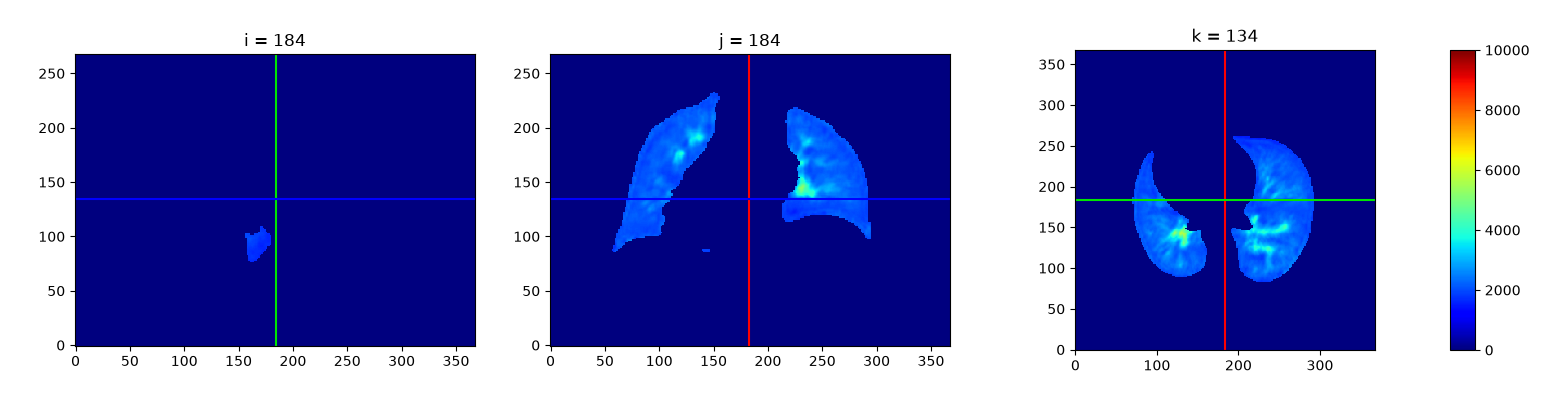

In [165]:
mpl_viz.SliceViewer(E_p_m, vox_spacing=vox_spacing, ax_width=4, ax_height=3, **E_p_kws)

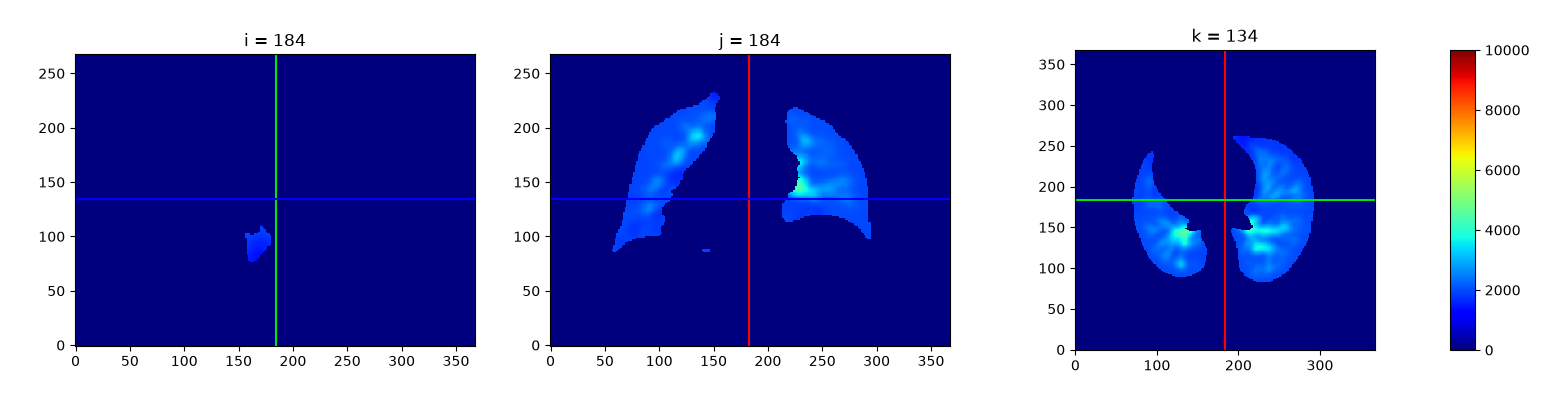

In [166]:
mpl_viz.SliceViewer(E_t_m, vox_spacing=vox_spacing, ax_width=4, ax_height=3, **E_t_kws)

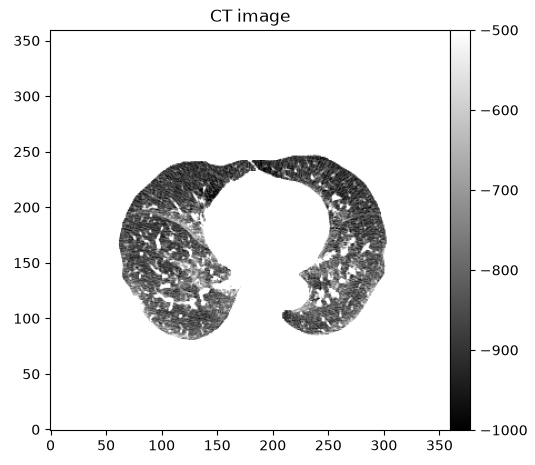

In [30]:
fig, ax, cax = mpl_viz.subplot_grid(1, 1, 4, 4, **grid_kws)
ax[0,0].set_title('CT image')
im = ax[0,0].imshow(img_m[:,:,z].T, origin='lower', **img_kws)
plt.colorbar(im, cax)

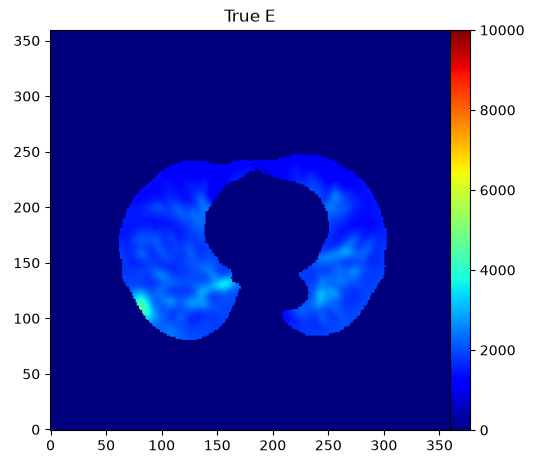

In [31]:
fig, ax, cax = mpl_viz.subplot_grid(1, 1, 4, 4, **grid_kws)
ax[0,0].set_title('True E')
im = ax[0,0].imshow(E_t_m[:,:,z].T, origin='lower', **E_t_kws)
plt.colorbar(im, cax)

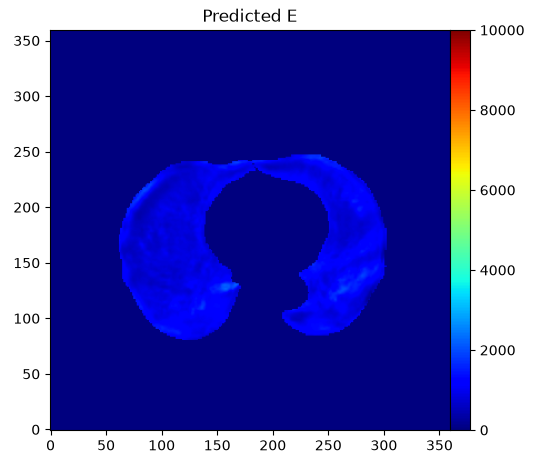

In [32]:
fig, ax, cax = mpl_viz.subplot_grid(1, 1, 4, 4, **grid_kws)
ax[0,0].set_title('Predicted E')
im = ax[0,0].imshow(E_p_m[:,:,z].T, origin='lower', **E_p_kws)
plt.colorbar(im, cax)

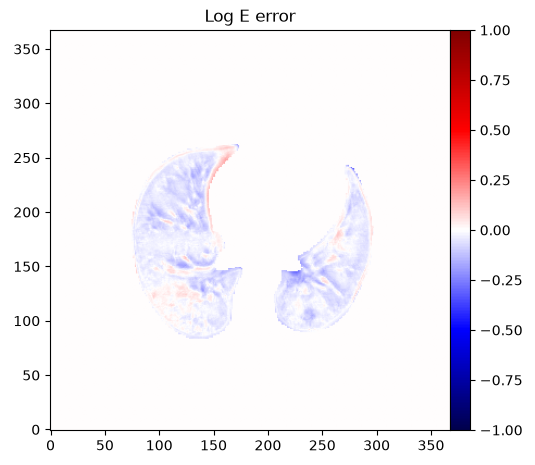

In [34]:
fig, ax, cax = mpl_viz.subplot_grid(1, 1, 4, 4, **grid_kws)
ax[0,0].set_title('Log E error')
im = ax[0,0].imshow(err_m[:,:,z].T, origin='lower', **err_kws)
plt.colorbar(im, cax)